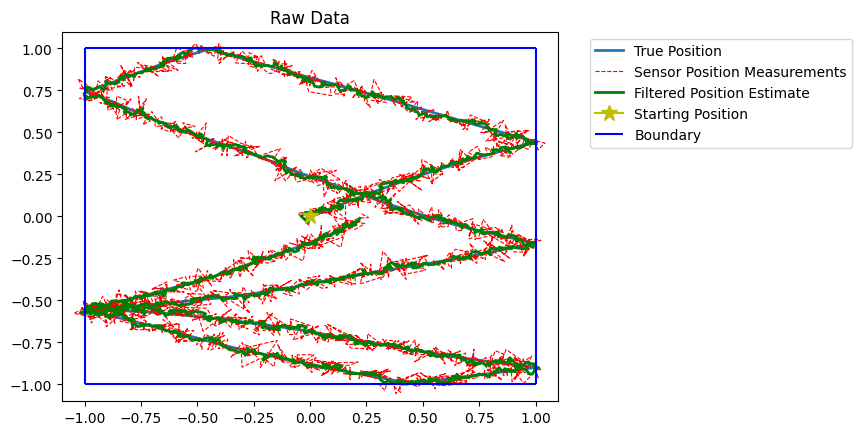

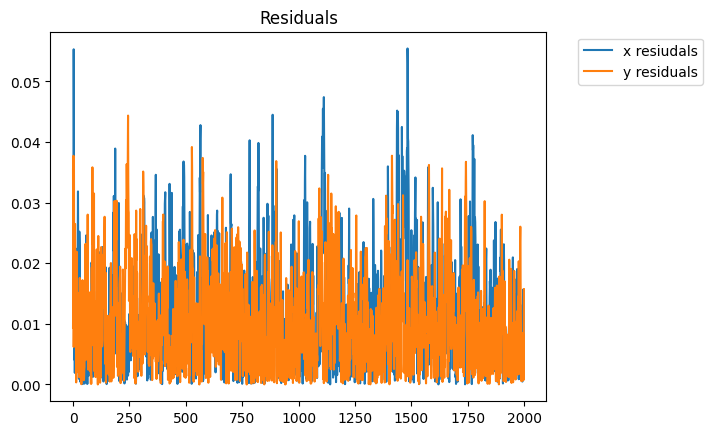

(0.0, 2.0)

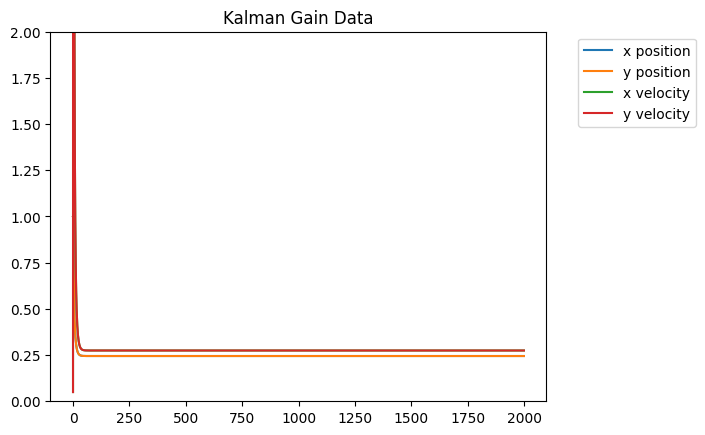

In [74]:
import numpy as np
import matplotlib.pyplot as plt

class KalmanFilter:
    def __init__(self, dim_x, dim_z, dim_u = 0):
        """
        The following are place holder objects and must be defined appropriately after calling the class.
        dim_x is the dimension of the state vector
        dim_z is the dimension of the measurement
        dim_u is the dimension of the driving force
        """
        self.x = np.zeros((dim_x, 1))       #State
        self.P = np.eye(dim_x)              #Error Covariance Matrix
        self.Q = np.eye(dim_x)              #Process Variance
        self.R = np.eye(dim_z)              #Measurement Variance
        self.u = np.zeros((dim_u, 1))       #Driving Force
        self.B = np.zeros((dim_x, dim_u))   #Control Transition Matrix
        self.F = np.zeros((dim_x, dim_x))   #State Transition Matrix
        self.H = np.zeros((dim_z, dim_x))   #Measurement Function
        self._I = np.eye(dim_x)             #Identity Matrix
        self.K = np.zeros((dim_x, dim_z))   #Kalman Gain
        self.dim_z = dim_z

    def predict(self):
        """
        Filter produces an a priori estimate of the next position off of the current estimate.
        """
        self.x = (self.F @ self.x) + (self.B @ self.u)
        self.P = (self.F @ self.P @ self.F.T) + self.Q

    def update(self, z):
        """
        Filter produces an a posteriori estimate by combining the a priori estimate with an observation.
        z - observation
        """
        z = np.asarray(z).reshape(self.dim_z, 1)
        self.K = self.P @ self.H.T @ np.linalg.inv(self.H @ self.P @ self.H.T + self.R)
        self.x = self.x + self.K @ (z - self.H @ self.x)
        self.P = (self._I - self.K @ self.H) @ self.P @ (self._I - self.K @ self.H).T + (self.K @ self.R @ self.K.T)

#Sensor object taking in a true position and adding white noise.
class Sensor:
    def __init__(self, measure_variance):
        self.r = measure_variance

    def sense(self, x):
        return x + np.random.normal(0, np.sqrt(self.r), size = x.shape)

#Ball object simulating motion of a ball confined to a box, assuming no energy loss.
class Ball:
    def __init__(self, initial_velocity, initial_pos, x_bounds, y_bounds, F, process_variance):
        self.x = np.array([[initial_pos[0]],
                           [initial_pos[1]],
                           [initial_velocity[0]],
                           [initial_velocity[1]]])
        self.x_upper = x_bounds[1]
        self.x_lower = x_bounds[0]
        self.y_upper = y_bounds[1]
        self.y_lower = y_bounds[0]
        self.F = F
        self.Q = process_variance

    #If the ball reaches a boundary in one plane its velocity is reversed in that plane
    def move(self):
        test = self.F @ self.x
        if test[0] >= self.x_upper or test[0] <= self.x_lower:
            self.x[2] *= -1
        if test[1] >= self.y_upper or test[1] <= self.y_lower:
            self.x[3] *= -1
        next = self.F @ self.x
        
        self.x = next + np.array([[0],[0], [np.random.normal(0, np.sqrt(self.Q))], [np.random.normal(0, np.sqrt(self.Q))]])
        
#Initial Conditions
h = 0.05
max_steps = 2000
processvariance = 0.000001
measurevariance = 0.001

F = np.array([[1, 0, h, 0],
              [0, 1, 0, h],
              [0, 0, 1, 0],
              [0, 0, 0, 1]])

obj = Ball([0.1,0.05], [0,0], [-1,1], [-1,1], F, processvariance)
sensor = Sensor(measurevariance)

filter = KalmanFilter(4, 2, dim_u=0)
filter.F = F
filter.H = np.array([[1,0,0,0],         #Picks out only x position and y position of the state vector
                      [0,1,0,0]])

filter.R = np.eye(2) * measurevariance

#Covariance matrix for process variance, with 0 covariance between x and y directions
filter.Q = np.array([[1, 0, 1, 0],
                     [0, 1, 0, 1],
                     [1, 0, 2, 0],
                     [0, 1, 0, 2]]) * processvariance * 50

filter.x = np.zeros([4,1])                  #Initial position and velocity are given as all 0 to the filter
filter.P = np.eye(4) * 500             #Very high initial covariance tells the filter the initial position and velocity are incorrect and should not be regarded

#Data storage for plots
x_data, y_data = [], []
x_sensor, y_sensor = [], []
x_filter, y_filter = [], []
x_residuals, y_residuals = [], []
K_data_x, K_data_y = [], []
K_data_vx, K_data_vy = [], []

#Simulation process
for i in range(max_steps):
    filter.predict()                                            #Filter produces an a priori estimate
    sense = sensor.sense(np.array([obj.x[0], obj.x[1]]))        #Sensor measures position with some error
    filter.update(sense)                                        #Filter uses measurement to produce a posteriori measurement

    #Storing data
    x_sensor.append(sense[0])
    y_sensor.append(sense[1])
    x_data.append(obj.x[0])
    y_data.append(obj.x[1])
    x_filter.append(filter.x[0])
    y_filter.append(filter.x[1])
    x_residuals.append(abs(filter.x[0] - obj.x[0]))
    y_residuals.append(abs(filter.x[1] - obj.x[1]))
    K_data_x.append(filter.K[0,0])
    K_data_y.append(filter.K[1,1])
    K_data_vx.append(filter.K[2,0])
    K_data_vy.append(filter.K[3,1])

    obj.move()                                                     #Ball moves with some process variance

#Raw Data Plot
plt.plot(x_data, y_data, lw = 2, label="True Position")
plt.plot(x_sensor, y_sensor, color = 'r', ls = '--', lw = 0.8, label = "Sensor Position Measurements")
plt.plot(x_filter, y_filter, lw = 2, color = 'g', label = "Filtered Position Estimate")
plt.plot([0], [0], marker='*', markersize = 12,  label='Starting Position', color="y")
plt.xlim(-1.1,1.1)
plt.ylim(-1.1,1.1)
plt.hlines(y=1, xmin=-1, xmax=1, colors='b', label="Boundary")
plt.hlines(y=-1, xmin=-1, xmax=1, colors='b')
plt.vlines(x=-1, ymin=-1, ymax=1, colors='b')
plt.vlines(x=1, ymin=-1, ymax=1, colors='b')
plt.title("Raw Data")
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
plt.show()

#Residuals Plot
plt.plot(x_residuals, label = 'x resiudals')
plt.plot(y_residuals, label='y residuals')
plt.title("Residuals")
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
plt.show()

#Kalman Gain Plot
plt.plot(K_data_x, label = 'x position')
plt.plot(K_data_y, label = 'y position')
plt.plot(K_data_vx, label = 'x velocity')
plt.plot(K_data_vy, label = 'y velocity')
plt.legend(bbox_to_anchor=(1.05, 1.0), loc='upper left')
plt.title("Kalman Gain Data")
plt.ylim(0, 2)

